In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files

df_raw = pd.read_excel('Telco_customer_churn.xlsx')

print("Dataset loaded successfully.")
print("Original dataset shape:", df_raw.shape)
display(df_raw.head())

Dataset loaded successfully.
Original dataset shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


# **Overview**

In [ ]:
print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

print("\\nColumn names:")
print(df_raw.columns.tolist())

print("\\nData types and non-null counts:")
df_raw.info()


Number of rows: 7043
Number of columns: 33
\nColumn names:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City            

In [ ]:
df_raw['Churn Label'].value_counts()

,count
Churn Label,
No,5174
Yes,1869


Initial data-quality checks



In [ ]:
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Missing values:")
display(df_raw.isna().sum())

Exact duplicate rows: 0
Missing values:


,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


## Making a working copy and clean data types

 `df_raw` unchanged, `df` for cleaning and analysis.



In [ ]:
df = df_raw.copy()

# Remove exact duplicate rows, if any are present
df = df.drop_duplicates().copy()

# Remove leading and trailing spaces from text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

# Convert Total Charges to numeric; invalid or blank values become NaN
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

# Check the result
print("Shape after removing exact duplicates:", df.shape)
print("Missing Total Charges:", df["Total Charges"].isna().sum())
print("Total Charges data type:", df["Total Charges"].dtype)

display(df[["Tenure Months", "Monthly Charges", "Total Charges"]].describe().T)

Shape after removing exact duplicates: (7043, 33)
Missing Total Charges: 11
Total Charges data type: Float64


,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
Monthly Charges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
Total Charges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8


In [ ]:
print("Churn Label values:")
display(df["Churn Label"].value_counts(dropna=False))

print("\\nChurn Value values:")
display(df["Churn Value"].value_counts(dropna=False))

print("\\nChurn Reason missing values:", df["Churn Reason"].isna().sum())

print("\\nNumeric summary:")
display(df[["Tenure Months", "Monthly Charges", "Total Charges", "CLTV"]].describe().T)

Churn Label values:


,count
Churn Label,
No,5174
Yes,1869


\nChurn Value values:


,count
Churn Value,
0,5174
1,1869


\nChurn Reason missing values: 5174
\nNumeric summary:


,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
Monthly Charges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
Total Charges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8
CLTV,7043.0,4400.295755,1183.057152,2003.0,3469.0,4527.0,5380.5,6500.0


## Removing The columns that are not useful for this project



In [ ]:
target_col = "Churn Label"

excluded_columns = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Value",
    "Churn Score",
    "Churn Reason",
    "CLTV"
]

print("Excluded columns:")
print(excluded_columns)

Excluded columns:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Churn Value', 'Churn Score', 'Churn Reason', 'CLTV']


## Exploratory Data Analysis (EDA)



###  Overall churn distribution



,Customer_Count
Churn Label,
No,5174
Yes,1869


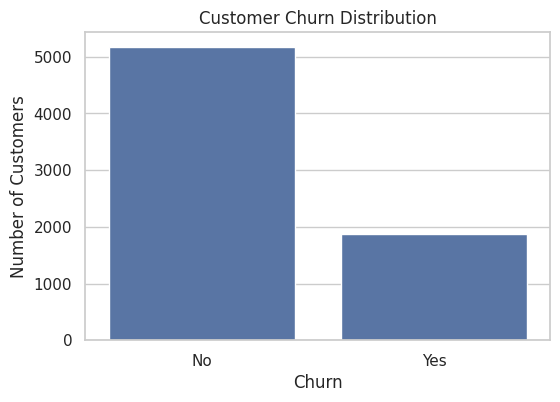

Churn percentage:


,Percentage
Churn Label,
No,73.46
Yes,26.54


In [ ]:
churn_counts = df[target_col].value_counts(dropna=False)
display(churn_counts.to_frame("Customer_Count"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target_col, order=["No", "Yes"])
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

churn_percent = df[target_col].value_counts(normalize=True).mul(100).round(2)
print("Churn percentage:")
display(churn_percent.to_frame("Percentage"))

### Numerical feature distributions


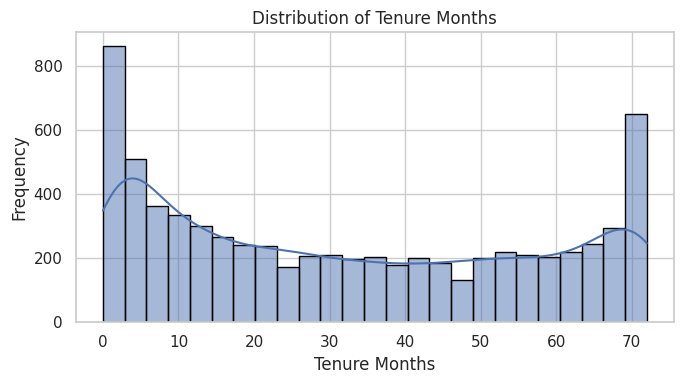

,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0


In [ ]:
# Tenure Months
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Tenure Months", bins=25, kde=True, edgecolor="black")
plt.title("Distribution of Tenure Months")
plt.xlabel("Tenure Months")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

display(df[["Tenure Months"]].describe().T)








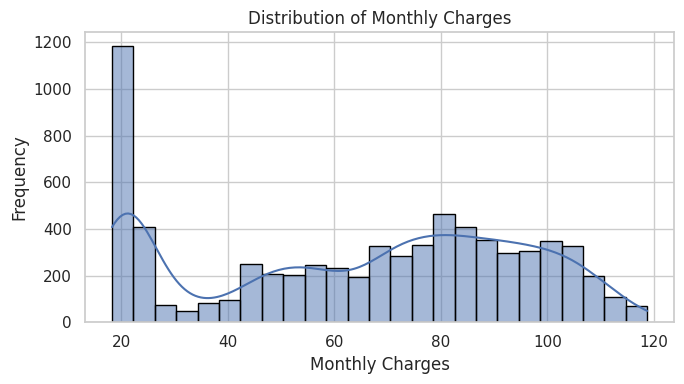

,count,mean,std,min,25%,50%,75%,max
Monthly Charges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [ ]:
# Monthly Charges
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Monthly Charges", bins=25, kde=True, edgecolor="black")
plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

display(df[["Monthly Charges"]].describe().T)

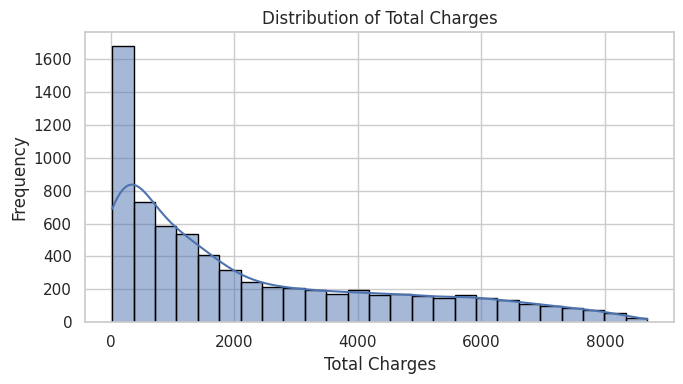

,count,mean,std,min,25%,50%,75%,max
Total Charges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8


In [ ]:
# Total Charges
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Total Charges", bins=25, kde=True, edgecolor="black")
plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

display(df[["Total Charges"]].describe().T)

### 9.3 Churn by contract type

This comparison helps us investigate whether churn rates differ across contract types. It shows association, not causation.

Churn Label,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


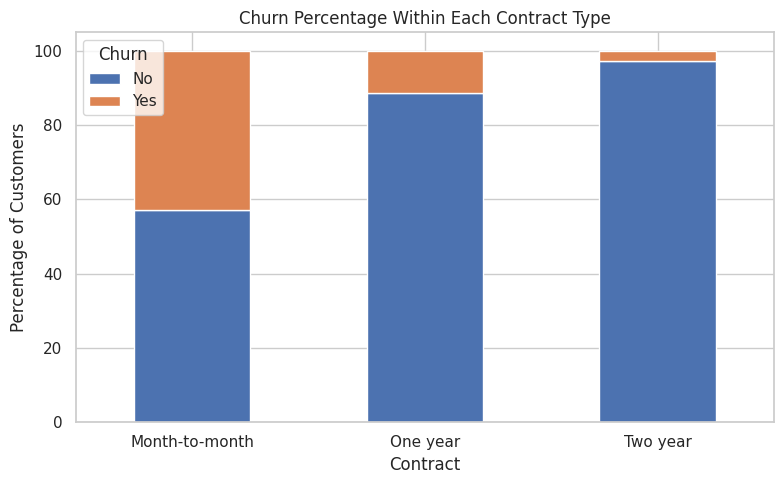

In [ ]:
contract_churn = pd.crosstab(
    df["Contract"],
    df[target_col],
    normalize="index"
).mul(100).round(2)

display(contract_churn)

contract_churn.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Churn Percentage Within Each Contract Type")
plt.xlabel("Contract")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [ ]:
avg_tenure= df.groupby("Churn Label")[["Tenure Months"]].mean()
display(avg_tenure)

,Tenure Months
Churn Label,
No,37.569965
Yes,17.979133


In [ ]:
num_cols = ["Tenure Months", "Monthly Charges", "Churn Value", "Churn Score", "CLTV"]
correlation_matrix= df[num_cols].corr()
display(correlation_matrix)

,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
Tenure Months,1.000000,0.247900,-0.352229,-0.224987,0.396406
Monthly Charges,0.247900,1.000000,0.193356,0.133754,0.098693
Churn Value,-0.352229,0.193356,1.000000,0.664897,-0.127463
Churn Score,-0.224987,0.133754,0.664897,1.000000,-0.079782
CLTV,0.396406,0.098693,-0.127463,-0.079782,1.000000


### Tenure and monthly charges by churn status



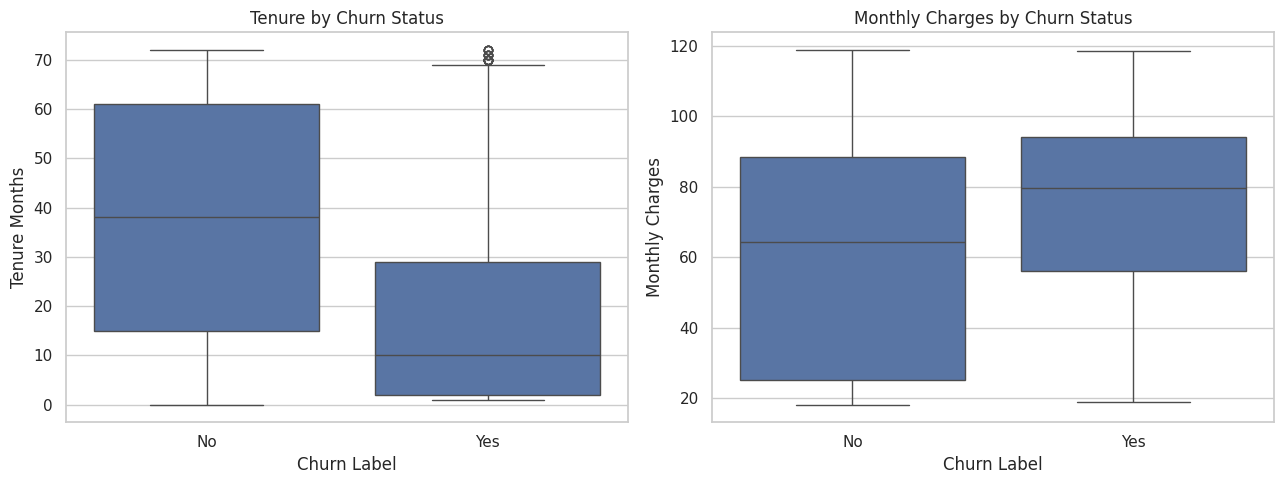

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x=target_col, y="Tenure Months", order=["No", "Yes"], ax=axes[0])
axes[0].set_title("Tenure by Churn Status")

sns.boxplot(data=df, x=target_col, y="Monthly Charges", order=["No", "Yes"], ax=axes[1])
axes[1].set_title("Monthly Charges by Churn Status")

plt.tight_layout()
plt.show()

### 9.5 Churn by internet service and payment method

These plots help identify customer groups worth investigating further.

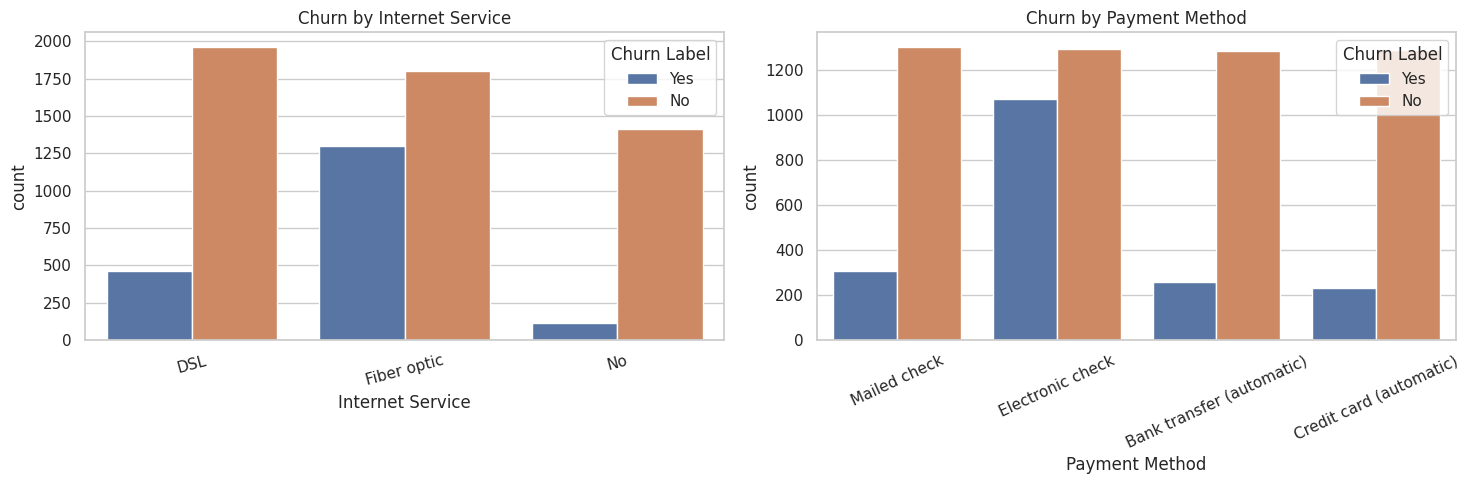

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df, x="Internet Service", hue=target_col, ax=axes[0])
axes[0].set_title("Churn by Internet Service")
axes[0].tick_params(axis="x", rotation=15)

sns.countplot(data=df, x="Payment Method", hue=target_col, ax=axes[1])
axes[1].set_title("Churn by Payment Method")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# **Tech_support**


In [ ]:
df['Tech Support'].unique()

<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: string

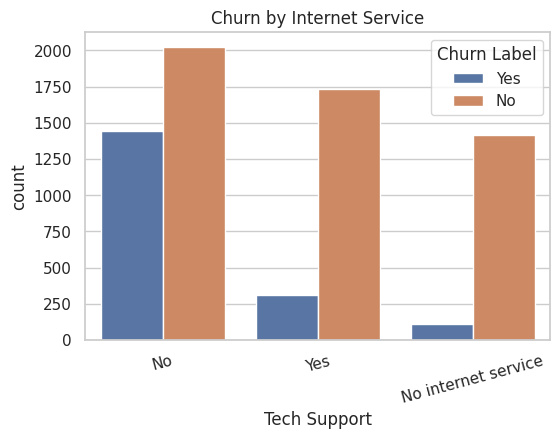

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Tech Support", hue=target_col)
plt.title("Churn by Internet Service")
plt.tick_params(axis="x", rotation=15)
plt.show()

### Correlation among numeric variables



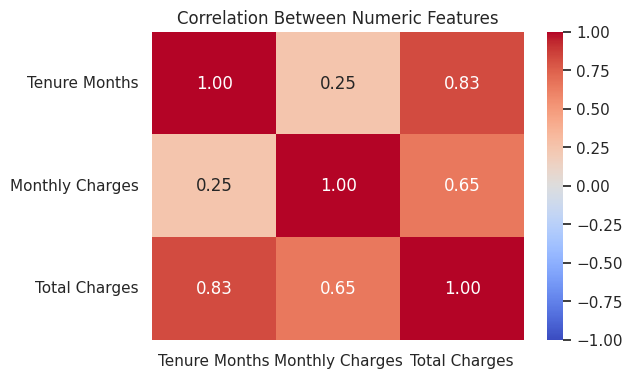

In [ ]:
numeric_corr_cols = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges"
]

corr = df[numeric_corr_cols].corr(numeric_only=True)

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Between Numeric Features")
plt.show()

# **Now ML**

# Customer Segmentation with K-Means

## Define features for clustering



In [ ]:
segmentation_features = [
    "Gender",
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Tenure Months",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Monthly Charges",
    "Total Charges"
]

X_segment = df[segmentation_features].copy()

print("Features used for clustering:", len(segmentation_features))
display(X_segment.head())

Features used for clustering: 19


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3


## Preprocessing the clustering features

K-Means groups records using distance. We scale numeric variables so variables measured in larger units do not dominate. Categorical variables are one-hot encoded so the model can process them.



In [ ]:
segment_num_cols = X_segment.select_dtypes(include=np.number).columns.tolist()
segment_cat_cols = X_segment.select_dtypes(exclude=np.number).columns.tolist()

try:
    segment_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    segment_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

segment_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            segment_num_cols
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", segment_encoder)
            ]),
            segment_cat_cols
        )
    ],
    verbose_feature_names_out=False
)

X_segment_processed = segment_preprocessor.fit_transform(X_segment)

print("Processed clustering data shape:", X_segment_processed.shape)

Processed clustering data shape: (7043, 46)


# **Final Converted Value**

In [ ]:
display(pd.DataFrame(X_segment_processed, columns=segment_preprocessor.get_feature_names_out()))

,Tenure Months,Monthly Charges,Total Charges,Gender_Female,Gender_Male,Senior Citizen_No,Senior Citizen_Yes,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,Phone Service_No,Phone Service_Yes,Multiple Lines_No,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_DSL,Internet Service_Fiber optic,Internet Service_No,Online Security_No,Online Security_No internet service,Online Security_Yes,Online Backup_No,Online Backup_No internet service,Online Backup_Yes,Device Protection_No,Device Protection_No internet service,Device Protection_Yes,Tech Support_No,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank transfer (automatic),Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,-1.236724,-0.362660,-0.959674,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,-1.236724,0.197365,-0.940470,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.992402,1.159546,-0.645186,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,-0.177995,1.330711,0.337349,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.677133,1.294151,1.216004,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1.613701,-1.449476,-0.380784,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
7039,-0.340876,0.665992,-0.128655,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
7040,1.613701,1.277533,2.243151,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
7041,-0.870241,-1.168632,-0.854469,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


## 12. Choosing the number of clusters (K)



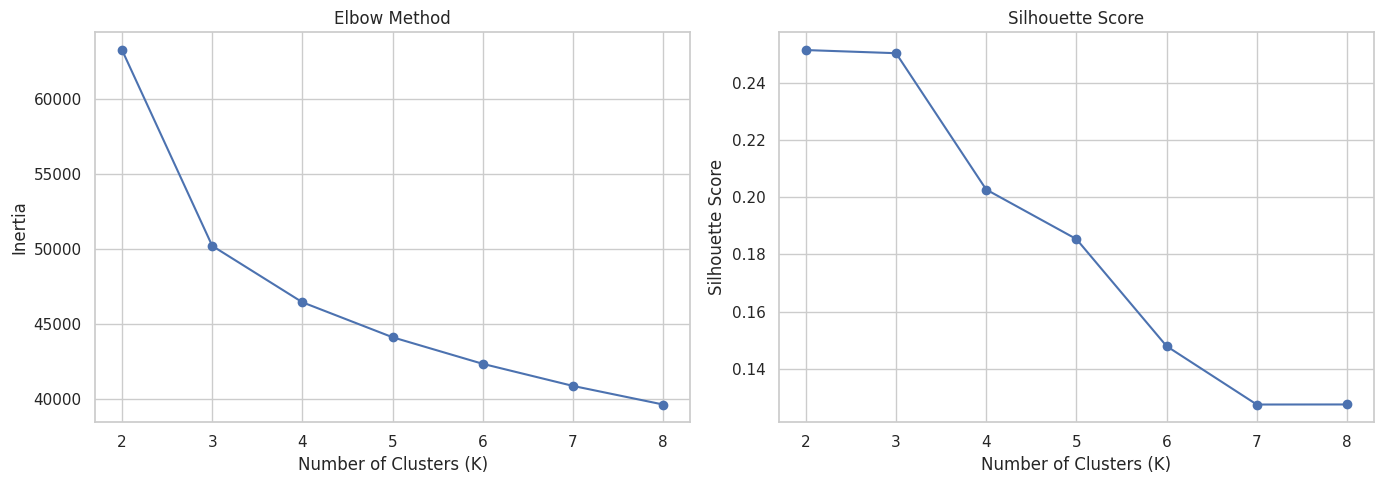

,K,Inertia,Silhouette_Score
0,2,63223.242064,0.251483
1,3,50194.115961,0.250382
2,4,46441.053888,0.202676
3,5,44113.621650,0.185348
4,6,42345.311900,0.147893
5,7,40876.554237,0.127465
6,8,39638.319895,0.127488


In [ ]:
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_segment_processed)
    inertias.append(km.inertia_)

    score = silhouette_score(
        X_segment_processed,
        labels,
        sample_size=min(2000, X_segment_processed.shape[0]),
        random_state=42
    )
    silhouette_scores.append(score)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

k_comparison = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette_Score": silhouette_scores
})
display(k_comparison)

##  Training the final K-Means model



In [ ]:
best_k = 4  # Change this after reviewing the previous plots

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["CustomerSegment"] = kmeans_model.fit_predict(X_segment_processed)

print("Customer count in each segment:")
display(df["CustomerSegment"].value_counts().sort_index().to_frame("Customers"))

Customer count in each segment:


,Customers
CustomerSegment,
0,1877
1,1645
2,1526
3,1995


##  Understanding the customer segments



In [ ]:
segment_numeric_profile = (
    df.groupby("CustomerSegment")[
        ["Tenure Months", "Monthly Charges", "Total Charges"]
    ]
    .mean()
    .round(2)
)

display(segment_numeric_profile)

segment_sizes = df["CustomerSegment"].value_counts().sort_index()
display(segment_sizes.to_frame("Customer_Count"))

for col in ["Contract", "Internet Service", "Payment Method", "Senior Citizen"]:
    print(f"\\n{col} distribution within each segment (%):")
    display(
        pd.crosstab(
            df["CustomerSegment"],
            df[col],
            normalize="index"
        ).mul(100).round(1)
    )

,Tenure Months,Monthly Charges,Total Charges
CustomerSegment,,,
0,15.54,84.60,1342.66
1,20.47,50.67,1059.83
2,30.55,21.08,665.22
3,59.41,91.13,5406.89


,Customer_Count
CustomerSegment,
0,1877
1,1645
2,1526
3,1995


\nContract distribution within each segment (%):


Contract,Month-to-month,One year,Two year
CustomerSegment,,,
0,95.5,4.1,0.4
1,70.5,21.9,7.5
2,34.3,23.9,41.8
3,19.9,33.6,46.4


\nInternet Service distribution within each segment (%):


Internet Service,DSL,Fiber optic,No
CustomerSegment,,,
0,1.9,98.1,0.0
1,99.8,0.2,0.0
2,0.0,0.0,100.0
3,37.3,62.7,0.0


\nPayment Method distribution within each segment (%):


Payment Method,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
CustomerSegment,,,,
0,13.9,12.8,63.0,10.2
1,17.4,18.5,31.7,32.3
2,21.8,21.7,8.0,48.6
3,33.3,32.3,27.0,7.4


\nSenior Citizen distribution within each segment (%):


Senior Citizen,No,Yes
CustomerSegment,,
0,72.1,27.9
1,89.1,10.9
2,96.6,3.4
3,80.6,19.4


###  Visualize the segments

This chart shows clusters using tenure and monthly charges. The clustering algorithm used all selected preprocessed features, not only these two axes.

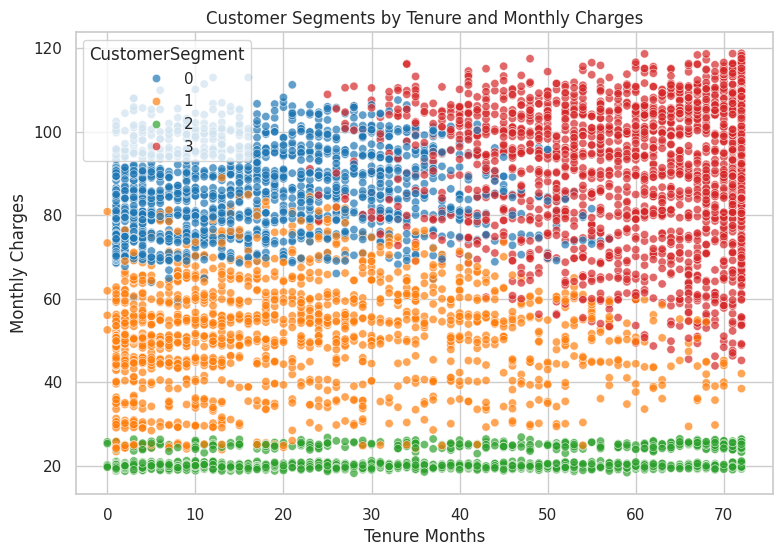

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Tenure Months",
    y="Monthly Charges",
    hue="CustomerSegment",
    palette="tab10",
    alpha=0.7
)
plt.title("Customer Segments by Tenure and Monthly Charges")
plt.show()

###  Comparing observed churn rates by segment



,Customers,Average_Tenure,Average_Monthly_Charges,Churn_Rate_Percent
CustomerSegment,,,,
0,1877,15.54,84.60,57.17
1,1645,20.47,50.67,25.41
2,1526,30.55,21.08,7.40
3,1995,59.41,91.13,13.28


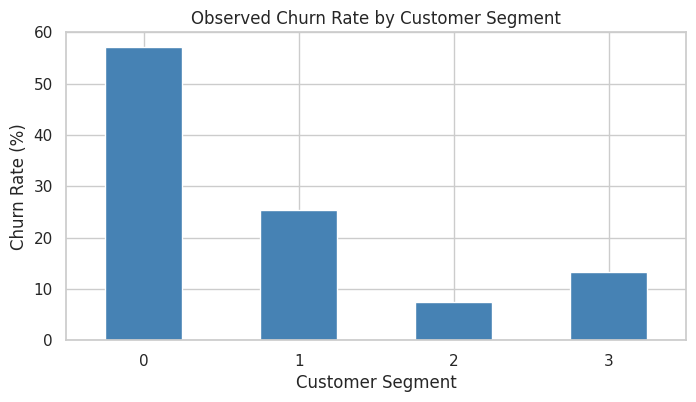

In [ ]:
segment_churn_profile = (
    df.groupby("CustomerSegment")
      .agg(
          Customers=("Churn Label", "size"),
          Average_Tenure=("Tenure Months", "mean"),
          Average_Monthly_Charges=("Monthly Charges", "mean"),
          Churn_Rate_Percent=("Churn Label", lambda s: (s == "Yes").mean() * 100)
      )
      .round(2)
)

display(segment_churn_profile)

segment_churn_profile["Churn_Rate_Percent"].plot(
    kind="bar",
    figsize=(8, 4),
    color="steelblue"
)
plt.title("Observed Churn Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

#  Churn Prediction with Random Forest

##  Define the prediction target and features

The target is `Churn Label`: `Yes` means the customer churned and `No` means the customer stayed. We map these values to 1 and 0.



In [ ]:
model_df = df.loc[df["Churn Label"].isin(["Yes", "No"])].copy()

y = model_df["Churn Label"].map({"No": 0, "Yes": 1})

prediction_exclusions = excluded_columns + [
    "Churn Label",
    "CustomerSegment"
]

X = model_df.drop(
    columns=prediction_exclusions,
    errors="ignore"
).copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\\nTarget distribution:")
display(y.value_counts().rename(index={0: "No Churn", 1: "Churn"}).to_frame("Count"))

Feature matrix shape: (7043, 19)
Target shape: (7043,)
\nTarget distribution:


,Count
Churn Label,
No Churn,5174
Churn,1869


## Split into training and test sets





In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("\\nChurn rate in training data:", round(y_train.mean() * 100, 2), "%")
print("Churn rate in test data:", round(y_test.mean() * 100, 2), "%")

Training rows: 5634
Testing rows: 1409
\nChurn rate in training data: 26.54 %
Churn rate in test data: 26.54 %


## Build the preprocessing pipeline



In [ ]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

try:
    churn_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    churn_encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

churn_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), num_cols),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", churn_encoder)
            ]),
            cat_cols
        )
    ],
    remainder="drop"
)

print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)

Numeric features: ['Tenure Months', 'Monthly Charges', 'Total Charges']
Categorical features: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


##  Train the Random Forest classifier



In [ ]:
rf_model = Pipeline([
    ("preprocessor", churn_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


##  Evaluate the model on the test set



In [ ]:
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})

display(metrics.round(4))

print("Classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.7899
1,Precision,0.5956
2,Recall,0.6497
3,F1-score,0.6215
4,ROC-AUC,0.8474


Classification report:
              precision    recall  f1-score   support

    No Churn       0.87      0.84      0.85      1035
       Churn       0.60      0.65      0.62       374

    accuracy                           0.79      1409
   macro avg       0.73      0.75      0.74      1409
weighted avg       0.80      0.79      0.79      1409



###  Confusion matrix



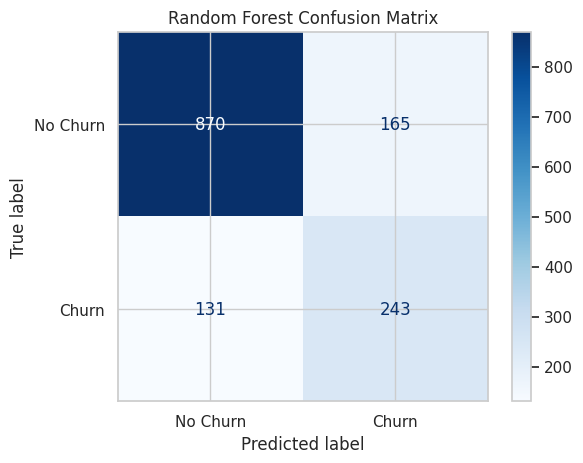

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    values_format="d"
)
plt.title("Random Forest Confusion Matrix")
plt.show()

###  ROC curve

ROC-AUC evaluates how well the model ranks churners above non-churners across classification thresholds. The curve uses predicted probabilities, not just the default 0.5 predictions.

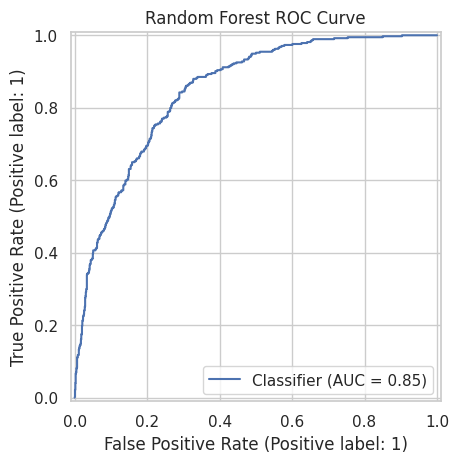

In [ ]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("Random Forest ROC Curve")
plt.show()

## Feature importance

We inspect the features the fitted Random Forest uses most. One-hot encoded categories appear as individual feature names.



,Feature,Importance
0,numeric__Tenure Months,0.119904
2,numeric__Total Charges,0.115449
1,numeric__Monthly Charges,0.092793
37,categorical__Contract_Month-to-month,0.090241
19,categorical__Online Security_No,0.047839
39,categorical__Contract_Two year,0.043042
28,categorical__Tech Support_No,0.039401
10,categorical__Dependents_Yes,0.036105
17,categorical__Internet Service_Fiber optic,0.034547
9,categorical__Dependents_No,0.032586


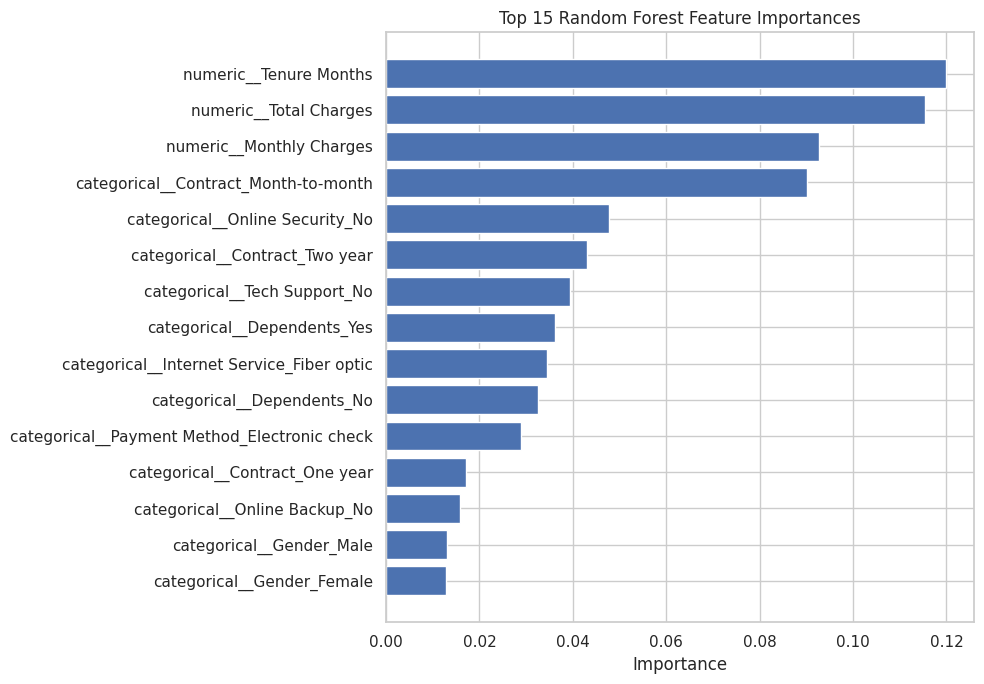

In [ ]:
fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_rf = rf_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
feature_importances = fitted_rf.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

top_importances = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_importances["Feature"], top_importances["Importance"])
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

##  tune Random Forest with cross-validation



In [ ]:
param_distributions = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [None, 8, 12, 18],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.7]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best cross-validation F1:", round(random_search.best_score_, 4))
print("Best parameters:")
print(random_search.best_params_)

best_rf_model = random_search.best_estimator_

# Evaluate the tuned model once on the held-out test set
tuned_pred = best_rf_model.predict(X_test)
tuned_prob = best_rf_model.predict_proba(X_test)[:, 1]

print("\\nTuned model test results")
print("Accuracy:", round(accuracy_score(y_test, tuned_pred), 4))
print("Precision:", round(precision_score(y_test, tuned_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, tuned_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, tuned_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, tuned_prob), 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best cross-validation F1: 0.6498
Best parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 8}
\nTuned model test results
Accuracy: 0.7608
Precision: 0.5346
Recall: 0.7647
F1-score: 0.6293
ROC-AUC: 0.8528


## 23. Save cleaned data, models, and results

This cell saves the cleaned dataset, the segmentation labels, the trained churn pipeline, and the K-Means artifacts. In Google Colab, files are saved in the current runtime and can be downloaded from the Files panel.

In [ ]:
# Save cleaned data with the descriptive customer segment labels
df.to_csv("telco_customer_churn_cleaned_with_segments.csv", index=False)

# Save the full classification pipeline
joblib.dump(rf_model, "telco_random_forest_baseline.joblib")

# Save the clustering artifacts and preprocessing together
joblib.dump(
    {
        "preprocessor": segment_preprocessor,
        "kmeans_model": kmeans_model,
        "features": segmentation_features,
        "selected_k": best_k
    },
    "telco_kmeans_segmentation.joblib"
)

# Save model evaluation metrics
metrics.to_csv("telco_random_forest_metrics.csv", index=False)

print("Files saved successfully.")

Files saved successfully.
